# XGBoost

Modelo de árboles de decisión (Chen y Guestrin, 2016) para pronosticar el precio de bolsa de la
semana siguiente, hora por hora. Se estima un modelo directo por horizonte, de $h = 3$ a $h = 7$. Los horizontes 8 y 9 usan
las variables y los hiperparámetros de $h = 7$, porque el modelo se diseñó con un alcance de 30
días y esos dos horizontes no tuvieron validación propia.

El código completo está en `2d_seleccion_variables.py` (variables) y `4_modelo_xgboost.ipynb`
(modelo), los dos en la raíz del repositorio. Este notebook muestra las partes principales y lee los resultados guardados en
`datos/resultados/modelo_xgboost/`. El test no se vuelve a correr. Lo único que se entrena aquí es el
modelo de $h = 3$ en 2022, que es parte de la validación.

## 1. Qué se pronostica

El objetivo es el mismo de los tres modelos: el cambio en logaritmo entre el precio del día $t + h$
y el último precio conocido, el del día $t$, a la misma hora $H$.

$$y_h = \ln P(t+h,\,H) - \ln P(t,\,H)$$

El pronóstico en pesos es $\hat P(t+h,H) = P(t,H)\,e^{\hat y_h}$. La referencia principal es el
ingenuo del día, que pronostica $\hat y_h = 0$, es decir, que el precio se queda igual.

In [1]:
from pathlib import Path
import json
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
import xgboost as xgb

# pandas 2.3 con numpy 2.5 avisa por una unidad interna de las fechas; no cambia nada
warnings.filterwarnings("ignore", message="The 'generic' unit for NumPy timedelta")

RAIZ = Path("datos")
PANELES = RAIZ / "paneles"
XGB = RAIZ / "resultados" / "modelo_xgboost"
SAR = RAIZ / "resultados" / "modelo_sarimax"
LSTM = RAIZ / "resultados" / "modelo_lstm_bloques"
HS = list(range(3, 10))

COLOR = {"precio real": "#2a78d6", "SARIMAX": "#1baf7a", "XGBoost": "#eb6834", "LSTM": "#eda100",
         "ingenuo del día": "#898781", "ingenuo semanal": "#c3c2b7"}
plt.rcParams.update({"figure.dpi": 110, "figure.facecolor": "white", "axes.grid": True,
                     "grid.color": "#e5e4df", "axes.edgecolor": "#c3c2b7", "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titlelocation": "left", "axes.titlesize": 11,
                     "legend.frameon": False})
pd.set_option("display.precision", 3)

## 2. Datos

El panel tiene una fila por día y hora. Cada variable entra con el atraso con el que se publica,
para no usar información que no se conocía el día del pronóstico. Como hay 24 filas por día, el
precio del mismo día y hora $h$ días después está $24h$ filas más abajo.

In [2]:
tabla = pd.read_csv(PANELES / "panel_horario_modelo.csv.gz", parse_dates=["fecha"])
seleccion = pd.read_csv(PANELES / "panel_horario_modelo_columnas.csv")
assert len(tabla) == tabla["fecha"].nunique() * 24

F = tabla["fecha"].to_numpy("datetime64[D]")
LP = np.log(tabla["precio"].to_numpy(float))


def adelante(x, k):
    out = np.full(len(x), np.nan)
    out[:-k] = x[k:]
    return out


Y = {h: adelante(LP, 24 * h) - LP for h in HS}
print(f"{len(tabla):,} filas, del {F.min()} al {F.max()}")

101,712 filas, del 2015-03-01 al 2026-10-06


## 3. Variables

De 134 variables base se construyeron 1.861 columnas candidatas: rezagos, medias móviles,
tendencias y medidas de variabilidad. La selección se hizo por separado para cada horizonte, en
tres pasos:

1. Limpieza con 2015-2019. Se quitan las columnas casi constantes, las inestables (más de 25% de
   sus valores de 2018-2019 fuera del rango de 2015-2017, porque un árbol no extrapola) y las que
   solo siguen a la tasa de cambio. De cada grupo de columnas con correlación mayor a 0,95 queda
   una.
2. Orden con 2015-2019. Un XGBoost con configuración fija se entrena con 2015-2017 y se evalúa en
   2018, y luego con 2015-2018 y se evalúa en 2019. Se agregan 10 columnas de ruido, copias de
   columnas reales con los días barajados. Siguen solo las columnas cuya importancia SHAP supera a
   la del mejor ruido en los dos años.
3. Número de columnas con 2020-2022. Se prueban las primeras 10, 20, 40, 80 y 160 del orden y se
   elige el número más pequeño cuyo error no supera al mejor en más de un error estándar.

In [3]:
pasos = {}
for h in range(3, 8):
    pasos[f"h = {h}"] = {"candidatas": (seleccion["tipo"] != "fija").sum(),
                         "tras la limpieza": (seleccion[f"limpieza_h{h}"] == "pasa").sum(),
                         "superan al ruido": seleccion[f"orden_h{h}"].notna().sum(),
                         "entran": ((seleccion[f"entra_h{h}"] == True) & (seleccion["tipo"] != "fija")).sum()}
pd.DataFrame(pasos)

,h = 3,h = 4,h = 5,h = 6,h = 7
candidatas,1861,1861,1861,1861,1861
tras la limpieza,1289,1290,1291,1290,1289
superan al ruido,15,43,89,99,117
entran,10,20,10,10,20


Además de esas columnas, todos los modelos tienen el precio del día $t$ (`lp`) y el calendario:
hora, día de la semana, mes, festivo, y el día de la semana y el festivo del día pronosticado.

Columnas elegidas para $h = 3$, en el orden de importancia del paso 2:

In [4]:
que_es = {
    "dlp_ma30d_mh": "precio de hoy frente a su media de 30 días a esa hora",
    "dlp_dia": "precio de esa hora frente a la media del día",
    "dlp_ma7d_mh": "precio de hoy frente a su media de 7 días a esa hora",
    "margen_ofertado_l3d": "capacidad ofertada sobre demanda, hace 3 días",
    "dlp_ultima": "precio de esa hora frente al de la última hora del día",
    "dlp_max_24h": "distancia del precio al máximo de las últimas 24 horas",
    "dlp_max_7d": "distancia del precio al máximo de 7 días a esa hora",
    "aportes_pct_sistema_delta_7d": "cambio semanal de los aportes hídricos",
    "presion_hidro_horaria_ultima": "demanda por cada MWh de aportes hídricos",
    "aportes_pct_sistema_l0d": "aportes hídricos en % de la media histórica",
}
h3 = seleccion[(seleccion["entra_h3"] == True) & (seleccion["tipo"] != "fija")].sort_values("orden_h3")
h3 = h3[["columna", "variable"]].reset_index(drop=True)
h3["qué mide"] = h3["columna"].map(que_es)
h3

,columna,variable,qué mide
0,dlp_ma30d_mh,lp,precio de hoy frente a su media de 30 días a e...
1,dlp_dia,lp,precio de esa hora frente a la media del día
2,dlp_ma7d_mh,lp,precio de hoy frente a su media de 7 días a es...
3,margen_ofertado_l3d,margen_ofertado,"capacidad ofertada sobre demanda, hace 3 días"
4,dlp_ultima,lp,precio de esa hora frente al de la última hora...
5,dlp_max_24h,lp,distancia del precio al máximo de las últimas ...
6,dlp_max_7d,lp,distancia del precio al máximo de 7 días a esa...
7,aportes_pct_sistema_delta_7d,aportes_pct_sistema,cambio semanal de los aportes hídricos
8,presion_hidro_horaria_ultima,presion_hidro_horaria,demanda por cada MWh de aportes hídricos
9,aportes_pct_sistema_l0d,aportes_pct_sistema,aportes hídricos en % de la media histórica


In [5]:
grupos = {}
for h in range(3, 8):
    e = seleccion[(seleccion[f"entra_h{h}"] == True) & (seleccion["tipo"] != "fija")]
    grupos[f"h = {h}"] = e["tipo"].replace({"precio": "del precio", "horaria": "horarias",
                                            "diaria": "diarias"}).value_counts()
pd.DataFrame(grupos).fillna(0).astype(int)

,h = 3,h = 4,h = 5,h = 6,h = 7
tipo,,,,,
del precio,6,9,6,7,9
diarias,2,7,1,0,6
horarias,2,4,3,3,5


La mayoría de las columnas elegidas son del precio pasado, sobre todo su distancia a las medias
recientes: el precio tiende a volver a su nivel. Las demás son del margen de oferta y de la
hidrología. En $h = 4$ y $h = 7$ entran 20 columnas, con más variables diarias de hidrología.

## 4. Hiperparámetros

Se eligieron con 2020-2022 en tres etapas:

1. Búsqueda al azar de 30 combinaciones en tres pliegues anuales: se entrena con todo lo anterior y
   se evalúa en 2020, 2021 y 2022.
2. Walk-forward mensual con las 3 mejores. Se elige la más simple de las que están a un error
   estándar de la mejor.
3. Tres variantes: pérdida Pseudo-Huber, entrenar solo con los últimos tres años y corregir el
   sesgo con el error de los últimos 30 días. Una variante entraba solo si bajaba el error en más
   de un error estándar.

In [6]:
print("Las 5 mejores de la búsqueda al azar para h = 3 (MSE en logaritmo):")
display(pd.read_csv(XGB / "etapa2_h3.csv").head(5))
print("Variantes para h = 3 (MSE y su error estándar):")
display(pd.read_csv(XGB / "etapa4_h3.csv"))

cfg = json.load(open(XGB / "configuracion_final.json", encoding="utf-8"))
print("Configuración final por horizonte:")
finales = pd.DataFrame({f"h = {h}": cfg[str(h)]["parametros"] for h in range(3, 8)}).T
finales.astype({"max_depth": int, "min_child_weight": int, "n_estimators": int})

Las 5 mejores de la búsqueda al azar para h = 3 (MSE en logaritmo):


,combinacion,max_depth,min_child_weight,subsample,colsample_bytree,reg_lambda,n_estimators,mse_2020,mse_2021,mse_2022,mse
0,25,4,50,0.75,0.82,8.39,200,0.038,0.023,0.051,0.037
1,3,5,240,0.71,0.79,1.50,150,0.039,0.024,0.050,0.038
2,18,5,50,0.89,0.70,2.66,150,0.039,0.024,0.050,0.038
3,15,6,50,0.74,0.54,3.80,150,0.038,0.024,0.051,0.038
4,5,5,10,0.72,0.77,4.44,200,0.039,0.023,0.051,0.038


Variantes para h = 3 (MSE y su error estándar):


,h,variante,mse,ee
0,3,base,0.038,0.004
1,3,pseudo_huber,0.039,0.004
2,3,tres_años,0.039,0.004
3,3,sesgo,0.042,0.004


Configuración final por horizonte:


,max_depth,min_child_weight,n_estimators,subsample,colsample_bytree,reg_lambda
h = 3,4,50,200,0.75,0.82,8.39
h = 4,5,240,200,0.71,0.79,1.50
h = 5,3,50,300,0.72,0.75,8.46
h = 6,4,240,200,0.88,0.74,5.36
h = 7,6,50,100,0.74,0.54,3.80


Ninguna variante entró. La regularización está en los hiperparámetros: `max_depth` limita la
profundidad de cada árbol, `min_child_weight` fija un mínimo de horas por hoja, `subsample` y
`colsample_bytree` son la fracción de filas y de columnas que ve cada árbol y `reg_lambda` penaliza
los valores grandes de las hojas. La tasa de aprendizaje es fija, 0,03.

Como 2020-2022 se usó para el número de columnas y para los hiperparámetros, el error de
validación es optimista. La medida que cuenta es la del test.

## 5. Entrenamiento y walk-forward

Estas son las funciones con las que se entrena y se pronostica, en una versión corta de las de
`4_modelo_xgboost.ipynb`. Para entrenar con corte en la fecha $c$ solo se usan las filas con
$t \le c - (h + 1)$: el objetivo de la fila $t$ es el precio de $t + h$, y así ningún precio que se
usa para entrenar es posterior al corte. El modelo se reentrena el primer día de cada mes y
pronostica desde cada día de ese mes.

In [7]:
COMUNES = dict(tree_method="hist", n_jobs=-1, random_state=0, learning_rate=0.03)


def columnas(h):
    c = seleccion[seleccion[f"entra_h{h}"] == True]
    return c.sort_values(f"orden_h{h}", na_position="first")["columna"].tolist()


def para_entrenar(h, corte):
    return (F <= corte - (h + 1)) & ~np.isnan(Y[h])


def ajustar(filas, h, p):
    modelo = xgb.XGBRegressor(**COMUNES, **p)
    return modelo.fit(tabla.loc[filas, columnas(h)].to_numpy(np.float32), Y[h][filas])


def walk_forward(h, p, cortes, fin, tope):
    idx, pred = [], []
    siguientes = list(cortes[1:]) + [fin + 1]
    for ini, sig in zip(cortes, siguientes):
        ev = (F >= ini) & (F < sig) & (F + h <= tope) & ~np.isnan(Y[h])
        modelo = ajustar(para_entrenar(h, ini), h, p)
        idx.append(np.flatnonzero(ev))
        pred.append(modelo.predict(tabla.loc[ev, columnas(h)].to_numpy(np.float32)))
    return np.concatenate(idx), np.concatenate(pred)

Para comprobar que estas funciones son las mismas del modelo, se corre el walk-forward de $h = 3$
en 2022 (un año de validación, 12 modelos) y se compara con el error diario guardado en esa etapa.

In [8]:
cortes = pd.date_range("2022-01-01", "2022-12-01", freq="MS").to_numpy().astype("datetime64[D]")
fin = np.datetime64("2022-12-31")
idx, pred = walk_forward(3, cfg["3"]["parametros"], cortes, fin, fin)

e = Y[3][idx] - pred
diario = pd.DataFrame({"fecha": pd.to_datetime(F[idx]), "mse": e ** 2}).groupby("fecha")["mse"].mean()
guardado = pd.read_csv(XGB / "etapa3_h3.csv.gz", parse_dates=["fecha"])
guardado = guardado[(guardado["combinacion"] == 25) & (guardado["fecha"].dt.year == 2022)].set_index("fecha")["mse_dia"]
print(f"{len(diario)} días; diferencia máxima con lo guardado: {np.abs(diario - guardado).max():.1e}")
print(f"2022, h = 3: RMSE {np.sqrt(np.mean(e ** 2)):.3f} frente a {np.sqrt(np.mean(Y[3][idx] ** 2)):.3f} del ingenuo del día")

362 días; diferencia máxima con lo guardado: 4.9e-08
2022, h = 3: RMSE 0.224 frente a 0.271 del ingenuo del día


El resultado coincide con lo guardado. Para ver qué usa el modelo, se toma el primero de esos 12
modelos (entrenado con los datos hasta diciembre de 2021) y se calcula la contribución SHAP de cada
columna en los pronósticos de 2022 (Lundberg y Lee, 2017). XGBoost la calcula directamente con
`pred_contribs=True`.

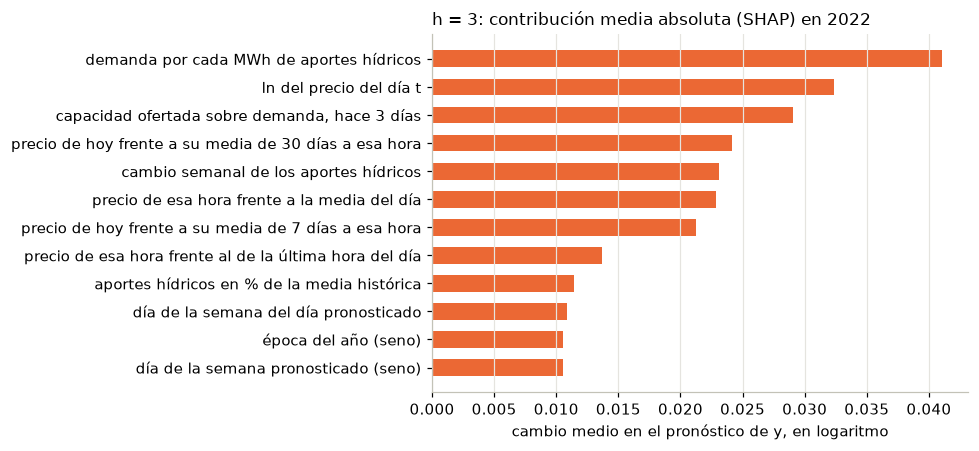

precio pasado    0.130
calendario       0.077
hidrología       0.076
oferta           0.029
Name: suma de la contribución, dtype: float32

In [9]:
modelo = ajustar(para_entrenar(3, cortes[0]), 3, cfg["3"]["parametros"])
en_2022 = (F >= cortes[0]) & (F + 3 <= fin)
cols = columnas(3)
contrib = modelo.get_booster().predict(xgb.DMatrix(tabla.loc[en_2022, cols].to_numpy(np.float32)),
                                       pred_contribs=True)
shap = pd.Series(np.abs(contrib[:, :-1]).mean(axis=0), index=cols).sort_values().tail(12)

nombres = dict(que_es, lp="ln del precio del día t", dia_semana_h3="día de la semana del día pronosticado",
               dia_semana_h3_sin="día de la semana pronosticado (seno)", dia_semana_h3_cos="día de la semana pronosticado (coseno)",
               es_festivo_h3="festivo el día pronosticado", hora_cos="hora del día (coseno)", hora_sin="hora del día (seno)",
               dia_ano_sin="época del año (seno)", dia_ano_cos="época del año (coseno)", dia_semana="día de la semana del día t",
               dia_semana_sin="día de la semana del día t (seno)", dia_semana_cos="día de la semana del día t (coseno)")
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.barh([nombres.get(c, c) for c in shap.index], shap, color=COLOR["XGBoost"], height=0.6)
ax.set_title("h = 3: contribución media absoluta (SHAP) en 2022")
ax.set_xlabel("cambio medio en el pronóstico de y, en logaritmo")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

todas = pd.Series(np.abs(contrib[:, :-1]).mean(axis=0), index=cols)
grupo = np.select([todas.index.str.startswith(("lp", "dlp")),
                   todas.index.str.startswith(("aportes", "presion_hidro")),
                   todas.index.str.startswith("margen")],
                  ["precio pasado", "hidrología", "oferta"], "calendario")
todas.groupby(grupo).sum().sort_values(ascending=False).rename("suma de la contribución")

La columna que más mueve el pronóstico en 2022 es la presión hidrológica de la última hora conocida
(demanda por cada MWh de aportes), seguida del precio del día $t$ y del margen de oferta. Sumadas,
las columnas del precio pasado pesan más que las de hidrología, pero ninguna sola supera a la
presión hidrológica.

## 6. Test: 2023-2025 y 2026

El test se corrió una vez, con el modelo congelado, reentrenando el primer día de cada mes. Aquí
se leen los pronósticos guardados. El criterio es el mismo de los tres modelos: el RMSE en
logaritmo debe ser al menos 5% menor que el del mejor ingenuo y la prueba de Diebold-Mariano
(Diebold y Mariano, 1995) contra ese ingenuo debe dar $p < 0{,}05$. La prueba usa el promedio
diario de la diferencia de los errores al cuadrado, con varianza de Newey-West (Newey y West, 1987).

In [10]:
BLOQUES = {"h = 3 a 9": HS, "h = 3": [3], "h = 3 a 7": [3, 4, 5, 6, 7], "h = 8 a 9": [8, 9]}


def rmse(e):
    return float(np.sqrt(np.mean(np.square(e))))


def newey_west(d, L):
    # media de una serie diaria y su error estándar con L rezagos
    u = d - d.mean()
    v = np.mean(u * u)
    for l in range(1, min(L, len(d) - 1) + 1):
        v += 2 * (1 - l / (L + 1)) * np.mean(u[l:] * u[:-l])
    return d.mean(), np.sqrt(v / len(d))


def diebold_mariano(e_a, e_b, fechas, L):
    # t negativo: a tiene menos error que b
    dif = np.square(np.asarray(e_a)) - np.square(np.asarray(e_b))
    d = pd.Series(dif).groupby(np.asarray(fechas)).mean().to_numpy()
    m, ee = newey_west(d, L)
    return m / ee, 2 * stats.norm.sf(abs(m / ee))


def criterio(g, pron="y_hat", bloques=BLOQUES):
    filas = []
    for nombre, hs in bloques.items():
        b = g[g["h"].isin(hs)]
        e = b["y"] - b[pron]
        ingenuos = {"del día": b["y"], "semanal": b["y"] - b["y_semanal"]}
        ref = min(ingenuos, key=lambda k: rmse(ingenuos[k]))
        t, p = diebold_mariano(e, ingenuos[ref], b["fecha"], max(hs) - 1 + 7)
        mejora = 100 * (1 - rmse(e) / rmse(ingenuos[ref]))
        filas.append({"bloque": nombre, "RMSE": rmse(e), "ingenuo": ref, "RMSE ingenuo": rmse(ingenuos[ref]),
                      "mejora (%)": mejora, "t": t, "p": p, "cumple": bool(mejora >= 5 and p < 0.05)})
    return pd.DataFrame(filas).set_index("bloque")

partes = [pd.read_csv(XGB / f"prueba_h{h}.csv.gz").assign(periodo="2023-2025") for h in HS]
partes.append(pd.read_csv(XGB / "prueba2026_mensual.csv.gz").query("3 <= h <= 9").assign(periodo="2026"))
xgb_test = pd.concat(partes, ignore_index=True)

xgb_test["fecha"] = pd.to_datetime(xgb_test["fecha"])
print(f"{len(xgb_test):,} pronósticos")
pd.concat({p: criterio(g) for p, g in xgb_test.groupby("periodo")}, names=["periodo"])

228,984 pronósticos


RMSE  ingenuo  RMSE ingenuo  mejora (%)      t  \
periodo   bloque                                                       
2023-2025 h = 3 a 9  0.443  del día         0.502      11.638 -4.824   
          h = 3      0.338  del día         0.411      17.903 -8.652   
          h = 3 a 7  0.413  del día         0.472      12.539 -6.242   
          h = 8 a 9  0.512  del día         0.570      10.109 -3.020   
2026      h = 3 a 9  0.392  del día         0.435       9.962 -3.287   
          h = 3      0.284  del día         0.352      19.455 -4.736   
          h = 3 a 7  0.361  del día         0.409      11.639 -3.705   
          h = 8 a 9  0.461  del día         0.496       7.153 -1.985   

                             p  cumple  
periodo   bloque                        
2023-2025 h = 3 a 9  1.407e-06    True  
          h = 3      5.074e-18    True  
          h = 3 a 7  4.308e-10    True  
          h = 8 a 9  2.524e-03    True  
2026      h = 3 a 9  1.013e-03    True  
          h = 3      2.181e-06    True  
          h = 3 a 7  2.110e-04    True  
          h = 8 a 9  4.711e-02    True

XGBoost cumple el criterio en todos los bloques y en los dos periodos: 11,6% de mejora en la semana
completa en 2023-2025 y 10,0% en 2026. El ingenuo del día es mejor que el semanal en todos los
bloques.

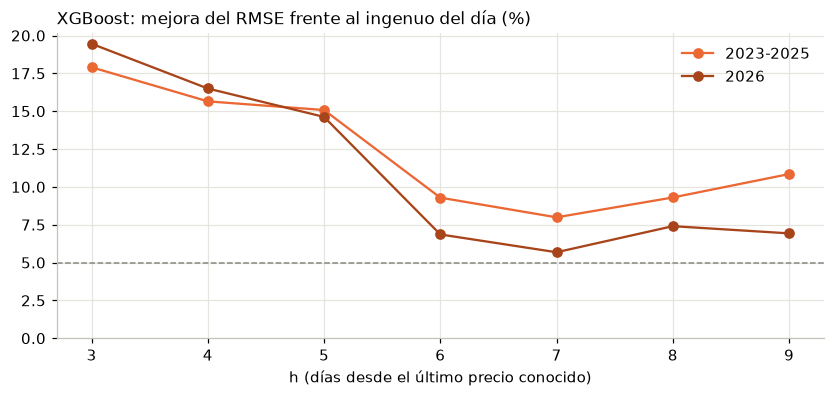

periodo,2023-2025,2026
h,,
3,17.9,19.5
4,15.7,16.5
5,15.1,14.6
6,9.3,6.9
7,8.0,5.7
8,9.3,7.4
9,10.8,6.9


In [11]:
por_h = (xgb_test.groupby(["periodo", "h"])
         .apply(lambda g: 100 * (1 - rmse(g["y"] - g["y_hat"]) / rmse(g["y"])), include_groups=False)
         .unstack("periodo"))

fig, ax = plt.subplots(figsize=(9, 3.6))
for periodo, color in [("2023-2025", COLOR["XGBoost"]), ("2026", "#a8441a")]:
    ax.plot(HS, por_h[periodo], marker="o", color=color, label=periodo)
ax.axhline(5, color="#898781", ls="--", lw=1)
ax.set_ylim(bottom=0)
ax.set_title("XGBoost: mejora del RMSE frente al ingenuo del día (%)")
ax.set_xlabel("h (días desde el último precio conocido)")
ax.legend()
plt.show()
por_h.round(1)

La mejora es grande en los tres primeros días, entre 15% y 20%, y cae a la mitad desde $h = 6$. En
2026 los horizontes 6 a 9 quedan cerca del umbral, y el bloque $h = 8$ a $9$ pasa justo
($p = 0{,}047$). El mínimo en $h = 7$ tiene la misma causa que en SARIMAX: ese día el ingenuo del
día ya es el mismo día de la semana que el pronosticado.

Por año, con el año del día del pronóstico. El sesgo es el promedio de $\hat y - y$: si es
negativo, el modelo pronosticó un precio más bajo que el real.

In [12]:
t = xgb_test[xgb_test["periodo"] == "2023-2025"]
por_año = pd.concat({a: criterio(g, bloques={"h = 3 a 9": HS}) for a, g in t.groupby(t["fecha"].dt.year)},
                    names=["año"]).droplevel("bloque")
por_año["sesgo (pron. - real)"] = t.groupby(t["fecha"].dt.year).apply(lambda g: (g["y_hat"] - g["y"]).mean(), include_groups=False)
por_año["cambio real medio"] = t.groupby(t["fecha"].dt.year)["y"].mean()
por_año[["RMSE", "RMSE ingenuo", "mejora (%)", "p", "cumple", "sesgo (pron. - real)", "cambio real medio"]]

,RMSE,RMSE ingenuo,mejora (%),p,cumple,sesgo (pron. - real),cambio real medio
año,,,,,,,
2023,0.474,0.544,12.861,9.145e-04,True,-0.062,-0.002
2024,0.470,0.508,7.642,9.992e-02,False,-0.063,-0.006
2025,0.379,0.447,15.266,2.082e-06,True,0.060,-0.002


La mejora no es estable entre años. En 2024 es 7,6% pero la diferencia con el ingenuo no es
significativa ($p = 0{,}10$), así que ese año el modelo no cumple el criterio. El sesgo cambia de
signo: en 2023 y 2024 el modelo pronosticó en promedio bajadas del precio de 6% que no ocurrieron
(el cambio real medio es casi cero) y en 2025 subidas de 6% que tampoco ocurrieron.

Otra forma de ver el error es la mediana, que no pesa tanto los días de cambios grandes:

In [13]:
mediana = pd.DataFrame({"XGBoost": (t["y"] - t["y_hat"]).abs().groupby(t["h"]).median(),
                        "ingenuo del día": t["y"].abs().groupby(t["h"]).median()})
mediana.loc["h = 3 a 9"] = [(t["y"] - t["y_hat"]).abs().median(), t["y"].abs().median()]
print("Mediana del error absoluto en logaritmo, 2023-2025")
mediana

Mediana del error absoluto en logaritmo, 2023-2025


,XGBoost,ingenuo del día
h,,
3,0.142,0.137
4,0.173,0.168
5,0.188,0.191
6,0.236,0.204
7,0.277,0.217
8,0.304,0.247
9,0.325,0.271
h = 3 a 9,0.225,0.203


En la mediana el ingenuo del día tiene menos error que XGBoost en 6 de los 7 horizontes y en la
semana completa (0,203 frente a 0,225). El modelo le gana en RMSE porque reduce los errores
grandes, los de los días en que el precio cambia mucho. En un día típico, cuando el precio casi no
se mueve, repetir el último precio conocido es difícil de superar.

### Resultados con el formato de Salazar-Peña et al. (2025)

Los resultados también se presentan como en Salazar-Peña et al. (2025), que compara una LSTM, una
Bi-LSTM y un Transformer para pronosticar irradiancia solar. Para cada modelo ese trabajo reporta
por horizonte el MAE, el RMSE, el nRMSE (el RMSE dividido por el promedio real), el MBE (el error
medio) y el MAPE, con un intervalo t al 95%, y el MAPE por hora del día. Aquí se calculan en
COP/kWh, con el pronóstico en pesos $\hat P = P(t,H)\,e^{\hat y}$. El skill score es la mejora
del RMSE frente al ingenuo del día, como en la figura 24 del paper, pero medida en pesos.

In [14]:
# El error es pronóstico menos real, en COP/kWh: un MBE negativo quiere decir que el modelo
# se quedó por debajo del precio real.
AZULES = ["#86b6ef", "#6da7ec", "#5598e7", "#3987e5", "#256abf", "#184f95", "#0d366b"]
COLOR_METRICA = {"MAE": "#5598e7", "RMSE": "#0d366b", "MBE": "#52514e"}
MESES = ["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"]
EJE_H = "h (días desde el último precio conocido)"


def metricas(g, pron):
    e = g[pron] - g["real"]
    r = np.sqrt(np.mean(e ** 2))
    return pd.Series({"MAE": e.abs().mean(), "RMSE": r, "nRMSE (%)": 100 * r / g["real"].mean(),
                      "MBE": e.mean(), "MAPE (%)": 100 * (e.abs() / g["real"]).mean()})


def por_horizonte(g, pron):
    # el intervalo t al 95% se calcula con el error promedio de cada día de pronóstico,
    # porque las 24 horas de un mismo día no son independientes
    filas = {}
    for h, x in g.groupby("h"):
        e = x[pron] - x["real"]
        dia = pd.DataFrame({"MAE": e.abs(), "MBE": e, "MSE": e ** 2}).groupby(x["fecha"]).mean()
        media = dia.mean()
        margen = stats.t.ppf(0.975, len(dia) - 1) * dia.std() / np.sqrt(len(dia))
        f = {}
        for m in ["MAE", "MBE", "MSE"]:
            f[m], f[m + " inf"], f[m + " sup"] = media[m], media[m] - margen[m], media[m] + margen[m]
        for c in ["", " inf", " sup"]:
            f["RMSE" + c] = np.sqrt(max(f["MSE" + c], 0))
            f["nRMSE" + c] = 100 * f["RMSE" + c] / x["real"].mean()
        f["MAPE"] = 100 * (e.abs() / x["real"]).mean()
        filas[h] = f
    return pd.DataFrame(filas).T


def figura_error(tablas, modelo):
    # como las figuras 15, 18 y 21 del paper
    fig, ejes = plt.subplots(1, len(tablas), figsize=(11, 3.8), sharey=True)
    for ax, (periodo, r) in zip(ejes, tablas.items()):
        ax.axhline(0, color="#898781", lw=0.8)
        for m in ["MAE", "RMSE", "MBE"]:
            ax.errorbar(r.index, r[m], yerr=[r[m] - r[m + " inf"], r[m + " sup"] - r[m]], color=COLOR_METRICA[m],
                        marker="o", ms=4, capsize=3, label=m)
        ax.set_title(periodo)
        ax.set_xticks(HS)
        ax.set_xlabel(EJE_H)
    ejes[0].set_ylabel("COP/kWh")
    ejes[0].legend()
    fig.suptitle(f"{modelo}: error por horizonte, con intervalo de 95%", x=0.01, ha="left", fontsize=11)
    plt.tight_layout()
    plt.show()


def figura_nrmse(tablas, colores, modelo):
    # como las figuras 16, 19 y 22 del paper
    fig, ax = plt.subplots(figsize=(8, 3.6))
    for periodo, r in tablas.items():
        ax.plot(r.index, r["nRMSE"], color=colores[periodo], marker="o", ms=4, label=periodo)
        ax.fill_between(r.index, r["nRMSE inf"], r["nRMSE sup"], color=colores[periodo], alpha=0.2, lw=0)
    ax.set_xticks(HS)
    ax.set_xlabel(EJE_H)
    ax.set_ylabel("%")
    ax.set_title(f"{modelo}: nRMSE por horizonte, con intervalo de 95%")
    ax.legend()
    plt.show()


def figura_mape_hora(g, pron, modelo):
    # como las figuras 17, 20 y 23 del paper: una curva por horizonte, de h = 3 (clara) a h = 9 (oscura)
    fig, ejes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
    for ax, (periodo, x) in zip(ejes, g.groupby("periodo")):
        mape = (100 * (x[pron] - x["real"]).abs() / x["real"]).groupby([x["hora"], x["h"]]).mean().unstack("h")
        for h, c in zip(HS, AZULES):
            ax.plot(mape.index, mape[h], color=c, lw=1.5, label=f"h = {h}")
        ax.set_title(periodo)
        ax.set_xticks([1, 4, 8, 12, 16, 20, 24])
        ax.set_xlabel("hora del día")
    ejes[0].set_ylabel("MAPE (%)")
    ejes[1].legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1))
    fig.suptitle(f"{modelo}: MAPE por hora del día y horizonte", x=0.01, ha="left", fontsize=11)
    plt.tight_layout()
    plt.show()


def figura_semana(s, columnas, titulo):
    # como las figuras 28 a 37 del paper: el pronóstico frente al real y su correlación de Pearson
    s = s.sort_values("momento")
    previo = s.drop_duplicates("hora").sort_values("hora")
    momento_previo = previo["t"] + pd.to_timedelta(previo["hora"] - 1, unit="h")
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 3.8), gridspec_kw={"width_ratios": [2.6, 1]})
    a1.plot(momento_previo, previo["ingenuo del día"], color="#52514e", lw=1.3, label="último día conocido")
    a1.plot(s["momento"], s["real"], color=COLOR["precio real"], lw=2, label="precio real")
    for c in columnas:
        estilo = {"ls": "--", "lw": 1.1} if c.startswith("ingenuo") else {"lw": 1.4}
        a1.plot(s["momento"], s[c], color=COLOR[c], label=c, **estilo)
        r = np.corrcoef(s["real"], s[c])[0, 1]
        a2.scatter(s[c], s["real"], s=8, color=COLOR[c], alpha=0.7, label=f"{c}, r = {r:.2f}".replace(".", ","))
    lim = [s[columnas + ["real"]].min().min(), s[columnas + ["real"]].max().max()]
    a2.plot(lim, lim, color="#898781", lw=0.8)
    dias = pd.date_range(previo["t"].iloc[0], s["momento"].max().normalize())
    a1.set_xticks(dias, [f"{x.day} {MESES[x.month - 1]}" for x in dias])
    a1.set_ylabel("COP/kWh")
    a1.set_title(titulo)
    a1.legend(ncol=3, fontsize=8)
    a2.set_xlabel("pronóstico (COP/kWh)")
    a2.set_ylabel("precio real (COP/kWh)")
    a2.set_title("Pronóstico frente al real")
    a2.legend(fontsize=8)
    plt.tight_layout()
    plt.show()

pesos = xgb_test.assign(real=xgb_test["precio_t"] * np.exp(xgb_test["y"]),
                        XGBoost=xgb_test["precio_t"] * np.exp(xgb_test["y_hat"]),
                        **{"ingenuo del día": xgb_test["precio_t"]})
semana = pd.DataFrame({(p, m): metricas(g, m) for p, g in pesos.groupby("periodo")
                       for m in ["XGBoost", "ingenuo del día"]}).T
ref = semana.xs("ingenuo del día", level=1)["RMSE"]
semana["skill score (%)"] = 100 * (1 - semana["RMSE"] / ref.reindex(semana.index.get_level_values(0)).to_numpy())
semana.round(1)

MAE   RMSE  nRMSE (%)   MBE  MAPE (%)  \
2023-2025 XGBoost          148.6  247.5       50.4 -46.4      36.2   
          ingenuo del día  150.1  257.1       52.3   1.3      40.1   
2026      XGBoost          122.5  175.7       36.0 -38.0      29.5   
          ingenuo del día  127.1  188.5       38.6  -8.3      32.4   

                           skill score (%)  
2023-2025 XGBoost                      3.7  
          ingenuo del día              0.0  
2026      XGBoost                      6.8  
          ingenuo del día              0.0

En pesos la ventaja de XGBoost es más pequeña que en logaritmo: el skill score de la semana es 3,7%
en 2023-2025 y 6,8% en 2026, frente a 11,6% y 10,0% del criterio. La diferencia está en el MBE. El
modelo pronostica en promedio 46 COP/kWh por debajo del precio real en 2023-2025, mientras el
ingenuo casi no tiene sesgo. XGBoost se entrenó para el error en logaritmo, y al volver a pesos
$e^{\hat y}$ se acerca a la mediana del precio, que queda por debajo de la media porque el precio
tiene picos hacia arriba (Duan, 1983). Además, en pesos pesan más los errores de los meses caros.
El MAE y el MAPE sí quedan por debajo de los del ingenuo en los dos periodos.

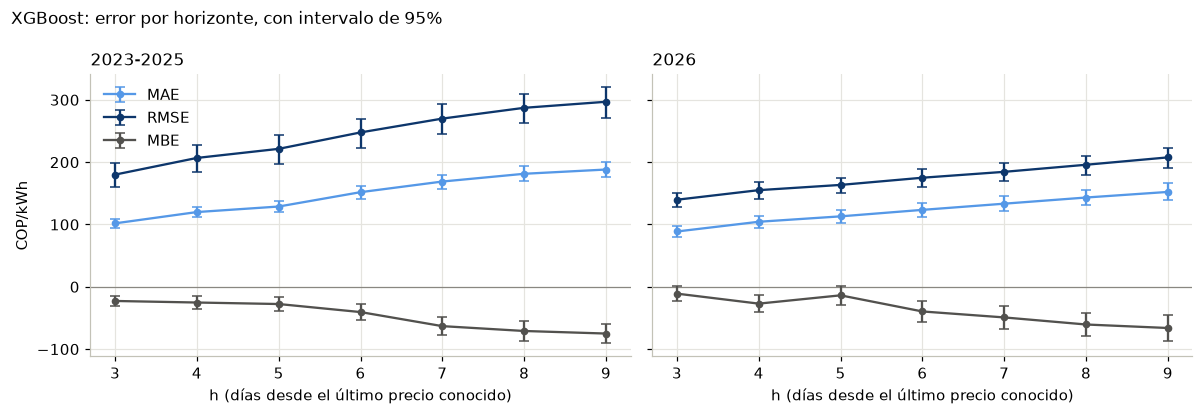

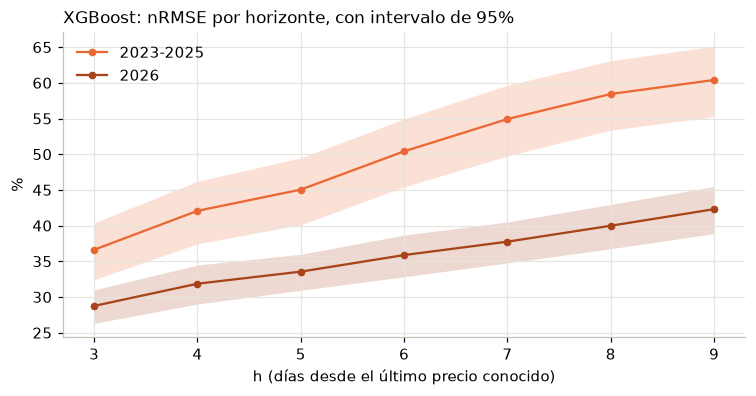

2023-2025                            2026                         
        MAE   RMSE nRMSE   MBE  MAPE    MAE   RMSE nRMSE   MBE  MAPE
3     101.8  180.0  36.6 -22.7  25.3   88.7  139.7  28.7 -11.0  20.6
4     119.9  206.8  42.1 -25.2  29.2  104.3  155.1  31.9 -27.0  24.4
5     128.8  221.4  45.0 -27.7  33.0  113.0  163.5  33.6 -13.7  27.9
6     151.8  247.7  50.4 -40.6  37.9  123.4  175.0  35.9 -39.6  30.4
7     168.9  269.9  54.9 -63.1  40.1  133.4  184.5  37.7 -49.2  32.6
8     181.3  287.2  58.4 -70.9  43.1  143.2  195.8  40.0 -60.5  34.2
9     188.2  296.9  60.4 -75.0  44.6  152.2  207.7  42.3 -66.1  36.4

In [15]:
tablas = {p: por_horizonte(g, "XGBoost") for p, g in pesos.groupby("periodo")}
figura_error(tablas, "XGBoost")
figura_nrmse(tablas, {"2023-2025": COLOR["XGBoost"], "2026": "#a8441a"}, "XGBoost")
pd.concat({p: r[["MAE", "RMSE", "nRMSE", "MBE", "MAPE"]] for p, r in tablas.items()}, axis=1).round(1)

El MAE y el RMSE crecen con el horizonte: en 2023-2025 el MAE va de 102 COP/kWh en $h = 3$ a 188
en $h = 9$, y el nRMSE de 37% a 60%. El MBE es negativo en todos los horizontes y crece con ellos,
de $-23$ a $-75$ COP/kWh en 2023-2025, sin que su intervalo toque el cero. Por ese sesgo, desde
$h = 7$ el RMSE en pesos de XGBoost queda casi igual al del ingenuo del día. En 2026 los errores
son más bajos (nRMSE de 29% a 42%) y el sesgo también es mayor en los últimos horizontes: de $-11$
COP/kWh en $h = 3$ a $-66$ en $h = 9$.

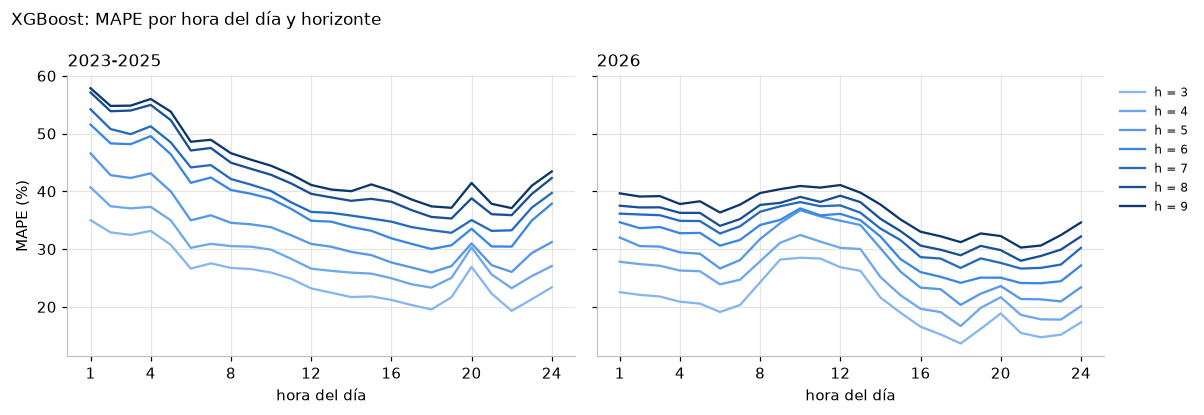

In [16]:
figura_mape_hora(pesos, "XGBoost", "XGBoost")

El MAPE crece con el horizonte en las 24 horas. En 2023-2025 es más alto en la madrugada, sobre
todo en la hora 1 (58% en $h = 9$), y más bajo en las horas 18 y 22. En 2026 los errores son menores
y los más altos pasan a la mañana, entre las horas 9 y 12.

### El alcance original de 30 días

XGBoost se diseñó para pronosticar 30 días. El alcance de una semana se definió después de ver su
prueba de 2026, donde más allá de $h = 7$ dejaba de superar al ingenuo. Para SARIMAX y la LSTM el
alcance de una semana ya estaba fijado antes de su test.

In [17]:
a30 = pd.concat({"2023-2025": pd.read_csv(XGB / "prueba_criterio.csv"),
                 "2026": pd.read_csv(XGB / "prueba2026_criterio.csv").query("plan == 'mensual'")},
                names=["periodo"]).droplevel(1)
a30.set_index("bloque", append=True)[["rmse_log", "mejor_ingenuo", "mejora", "dm_p", "funciona"]]

rmse_log mejor_ingenuo  mejora       dm_p  funciona
periodo   bloque                                                          
2023-2025 h = 3           0.338       del día  17.903  5.074e-18      True
          h = 3 a 7       0.413       del día  12.539  4.308e-10      True
          h = 8 a 14      0.546       del día  10.679  7.363e-03      True
          h = 15 a 30     0.615       del día  13.118  1.575e-02      True
2026      h = 3           0.284       del día  19.455  2.181e-06      True
          h = 3 a 7       0.361       del día  11.639  2.110e-04      True
          h = 8 a 14      0.509       del día   6.361  9.554e-02     False
          h = 15 a 30     0.619       semanal  -7.246  3.612e-01     False

En 2023-2025 el modelo cumplía el criterio hasta 30 días. En 2026 dejó de cumplirlo después de la
primera semana: 6,4% con $p = 0{,}096$ en $h = 8$ a $14$, y de 15 a 30 días quedó peor que el
ingenuo semanal. Con eso el alcance se redujo a la semana, que es lo que se sostiene en los dos
periodos. Como esa decisión se tomó viendo el test de 2026, el resultado de XGBoost en la semana de
2026 no es del todo independiente de ella.

### Semana del 9 al 15 de octubre de 2026

Pronóstico hecho con los precios conocidos hasta el 6 de octubre y guardado antes de descargar el
precio real de esa semana. Es una sola semana: muestra el comportamiento del modelo, no lo evalúa.

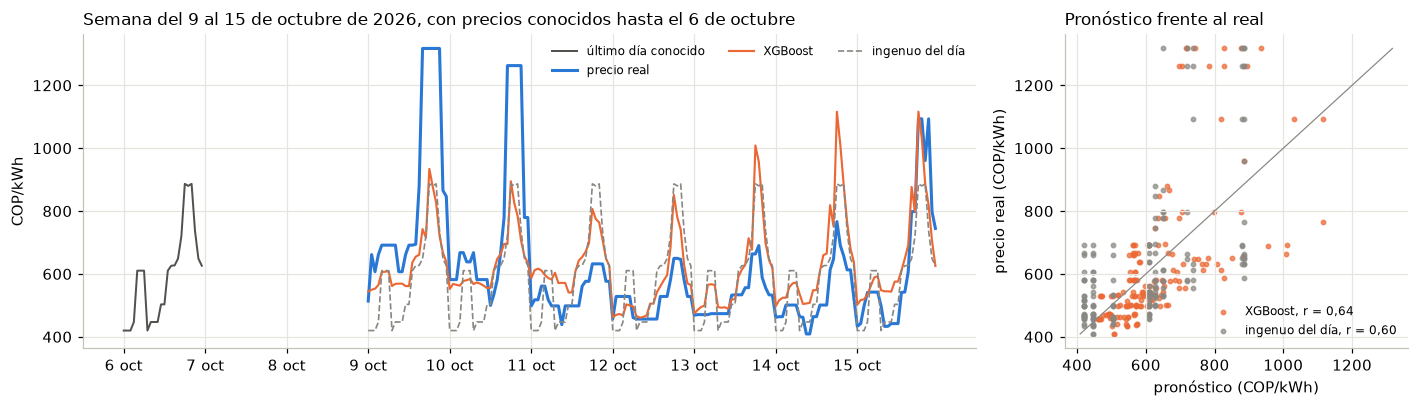

,XGBoost,ingenuo del día
RMSE en log,0.201,0.234
MAPE (%),15.942,18.715
MBE (COP/kWh),3.131,-31.991
r de Pearson,0.643,0.599


In [18]:
fin_x = pd.read_csv(XGB / "pronostico_final.csv", parse_dates=["origen", "fecha_objetivo"])
real = pd.read_csv(XGB / "precio_real_final.csv", parse_dates=["fecha_objetivo"])
sem = (fin_x.merge(real, on=["fecha_objetivo", "hora"])
       .rename(columns={"origen": "t", "precio_real": "real", "precio_pron": "XGBoost",
                        "precio_t": "ingenuo del día"}))
sem["momento"] = sem["fecha_objetivo"] + pd.to_timedelta(sem["hora"] - 1, unit="h")
figura_semana(sem, ["XGBoost", "ingenuo del día"],
              "Semana del 9 al 15 de octubre de 2026, con precios conocidos hasta el 6 de octubre")

pd.DataFrame({m: {"RMSE en log": rmse(np.log(sem["real"] / sem[m])),
                  "MAPE (%)": 100 * np.mean(np.abs(sem[m] / sem["real"] - 1)),
                  "MBE (COP/kWh)": np.mean(sem[m] - sem["real"]),
                  "r de Pearson": np.corrcoef(sem["real"], sem[m])[0, 1]}
              for m in ["XGBoost", "ingenuo del día"]}).round(3)

En esa semana XGBoost tuvo menos error que el ingenuo del día (0,201 frente a 0,234 en RMSE en
logaritmo y MAPE de 15,9% frente a 18,7%) y una correlación con el precio real algo mayor (0,64
frente a 0,60). Ninguno de los dos anticipó los precios altos del 9 y el 10 de octubre, y en las
noches del 13 y el 14 el modelo se pasó.

## Hallazgos

1. XGBoost cumple el criterio en todos los bloques y en los dos periodos: 11,6% de mejora en la
   semana completa en 2023-2025 y 10,0% en 2026. La ganancia está en los tres primeros días, entre
   15% y 20%, y baja a la mitad desde $h = 6$.
2. El resultado no es igual todos los años. En 2024 la mejora (7,6%) no es significativa, y el
   sesgo cambia de signo de un año a otro.
3. El modelo gana porque reduce los errores grandes. En la mediana, el ingenuo del día tiene menos
   error (0,203 frente a 0,225).
4. La mayoría de las variables elegidas son del precio pasado, pero la columna individual que más
   pesa en el pronóstico de 2022 es la presión hidrológica, seguida del margen de oferta.
5. A más de una semana el modelo no se sostiene: en 2026 deja de superar al ingenuo después de
   $h = 7$. El alcance de la tesis se fijó en una semana por esa razón.
6. En pesos, con el formato de Salazar-Peña et al. (2025), la ventaja es menor: skill score de 3,7%
   en 2023-2025 y 6,8% en 2026. El modelo se queda corto en promedio (MBE de $-46$ COP/kWh en
   2023-2025) y ese sesgo crece con el horizonte, hasta que desde $h = 7$ el RMSE en pesos queda
   igual al del ingenuo.

## Referencias

- Chen, T. y Guestrin, C. (2016). XGBoost: A scalable tree boosting system. En *Proceedings of the 22nd ACM SIGKDD International Conference on Knowledge Discovery and Data Mining* (pp. 785-794).
- Diebold, F. y Mariano, R. (1995). Comparing predictive accuracy. *Journal of Business & Economic Statistics*, 13(3), 253-263.
- Duan, N. (1983). Smearing estimate: a nonparametric retransformation method. *Journal of the American Statistical Association*, 78(383), 605-610.
- Lundberg, S. y Lee, S.-I. (2017). A unified approach to interpreting model predictions. En *Advances in Neural Information Processing Systems 30* (pp. 4765-4774).
- Newey, W. y West, K. (1987). A simple, positive semi-definite, heteroskedasticity and autocorrelation consistent covariance matrix. *Econometrica*, 55(3), 703-708.
- Salazar-Peña, N., Palma-Vergara, A., Montes-Vera, M., Vargas-Torres, M. A., Hernández Vanegas, R., Amador, M., Rojas, B., Salinas, A., Velasco, A., Tabares, A. y González-Mancera, A. (2025). Intra-day solar and power forecast for optimization of intraday market participation. *arXiv*, 2501.09551v3.